# Product Recommendation Model: Data Merge, EDA and Modelling

**Section owner:** Product Recommendation Model (Tasks 1 and 4)
**Goal:** merge `customer_transactions` and `customer_social_profiles`, explore the merged data, and build a model that predicts the `product_category` a customer will buy. The model is called by the command-line demo after face and voice verification.

**Contents**
1. Setup and loading the raw data
2. Cleaning and merge validation
3. Exploratory data analysis
4. Feature-signal check
5. Model training and evaluation
6. Using the model: `predict_product`
7. Conclusions and limitations

*Run order:* this notebook expects `data_merge.py`, `product_model.py`, `product_predictor.py` and `merged_dataset.csv` in the same folder (run `python data_merge.py` and `python product_model.py` first).

## 1. Setup and loading the raw data

In [1]:
import glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import data_merge as dm
import product_model as pm

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

# find the raw files regardless of whether the name uses spaces or underscores
TXN_FILE = glob.glob("customer_transactions*.csv")[0]
SOC_FILE = glob.glob("customer_social_profiles*.csv")[0]
print("Transactions file:", TXN_FILE); print("Social file      :", SOC_FILE)

txn_raw = pd.read_csv(TXN_FILE)
soc_raw = pd.read_csv(SOC_FILE)

Transactions file: customer_transactions_-_customer_transactions.csv
Social file      : customer_social_profiles_-_customer_social_profiles.csv


### 1.1 Raw data overview: shape, types, nulls, duplicates

In [2]:
for name, df in [("TRANSACTIONS", txn_raw), ("SOCIAL PROFILES", soc_raw)]:
    print(f"===== {name}: {df.shape[0]} rows x {df.shape[1]} columns =====")
    print(pd.DataFrame({"dtype": df.dtypes.astype(str), "nulls": df.isna().sum(),
                        "unique": df.nunique()}))
    print("Exact duplicate rows:", df.duplicated().sum(), "\n")

===== TRANSACTIONS: 150 rows x 6 columns =====
                      dtype  nulls  unique
customer_id_legacy    int64      0      75
transaction_id        int64      0     150
purchase_amount       int64      0     120
purchase_date           str      0     150
product_category        str      0       5
customer_rating     float64     10      37
Exact duplicate rows: 0 

===== SOCIAL PROFILES: 155 rows x 5 columns =====
                           dtype  nulls  unique
customer_id_new              str      0      84
social_media_platform        str      0       5
engagement_score           int64      0      50
purchase_interest_score  float64      0      40
review_sentiment             str      0       3
Exact duplicate rows: 5 



In [3]:
print("Transactions, first rows:"); display(txn_raw.head())
print("Social profiles, first rows:"); display(soc_raw.head())

Transactions, first rows:


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1
3,171,1004,256,2024-01-04,Clothing,2.8
4,160,1005,64,2024-01-05,Clothing,1.3


Social profiles, first rows:


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive
3,A162,Twitter,89,2.6,Positive
4,A197,Twitter,92,2.3,Neutral


**What we see**
- The key column is named and formatted differently in each file: transactions use an integer (`customer_id_legacy`, e.g. `151`) while social profiles use a string with a prefix (`customer_id_new`, e.g. `A151`). A direct join would match nothing.
- The social file contains exact duplicate rows, and (checked below) several rows per customer.
- `customer_rating` has missing values in the transactions file.

## 2. Cleaning and merge validation

### 2.1 Fix the key and check how the two files relate

In [4]:
soc_chk = soc_raw.copy()
soc_chk["customer_id"] = soc_chk["customer_id_new"].str.extract(r"(\d+)").astype(int)   # 'A151' -> 151
txn_chk = txn_raw.rename(columns={"customer_id_legacy": "customer_id"})

assert soc_chk["customer_id_new"].str.match(r"^A\d+$").all(), "unexpected ID format"
t_ids, s_ids = set(txn_chk.customer_id), set(soc_chk.customer_id)
print("Customers in transactions     :", len(t_ids))
print("Customers in social profiles  :", len(s_ids))
print("Customers in both             :", len(t_ids & s_ids))
print("Transaction customers WITHOUT a social profile:", len(t_ids - s_ids))
print("Social customers with no transactions        :", len(s_ids - t_ids))
print()
print("Social rows per customer (raw):")
print(soc_chk.groupby("customer_id").size().value_counts().sort_index().rename("n_customers").to_frame().rename_axis("rows_per_customer"))

Customers in transactions     : 75
Customers in social profiles  : 84
Customers in both             : 61
Transaction customers WITHOUT a social profile: 14
Social customers with no transactions        : 23

Social rows per customer (raw):
                   n_customers
rows_per_customer             
1                           43
2                           22
3                           14
4                            1
5                            3
7                            1


### 2.2 Why a naive merge is wrong
Social profiles are **not unique per customer**. Joining directly would repeat each transaction once per matching social row and distort the dataset (and the class balance). The cell below measures the damage.

Exact duplicate social rows removed: 5
Original transactions                         150
Naive inner join                              219
Naive left join (no dedupe/aggregate)         252
Our merge (dedupe + aggregate + left join)    150


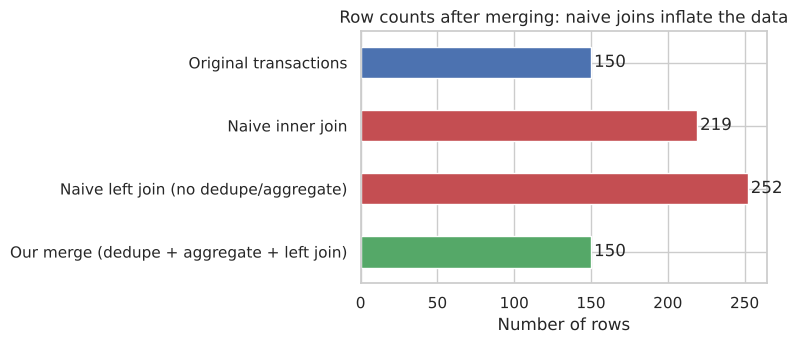

In [5]:
naive_inner = txn_chk.merge(soc_chk, on="customer_id", how="inner")
naive_left  = txn_chk.merge(soc_chk, on="customer_id", how="left")

soc_dedup = soc_chk.drop_duplicates()
print("Exact duplicate social rows removed:", len(soc_chk) - len(soc_dedup))

txn_c, soc_c = dm.load_and_clean(TXN_FILE, SOC_FILE)        # cleaned versions (dedupe, types)
soc_agg = dm.aggregate_social(soc_c)                        # ONE row per customer
final_left = txn_c.merge(soc_agg, on="customer_id", how="left")

counts = pd.Series({
    "Original transactions": len(txn_raw),
    "Naive inner join": len(naive_inner),
    "Naive left join (no dedupe/aggregate)": len(naive_left),
    "Our merge (dedupe + aggregate + left join)": len(final_left),
})
print(counts.to_string())

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = ["#4C72B0", "#C44E52", "#C44E52", "#55A868"]
counts.iloc[::-1].plot.barh(ax=ax, color=colors[::-1])
ax.set_xlabel("Number of rows"); ax.set_title("Row counts after merging: naive joins inflate the data")
for i, v in enumerate(counts.iloc[::-1]): ax.text(v + 2, i, str(v), va="center")
plt.tight_layout(); plt.show()

**Join logic (justification).** We use a **left join from transactions** because each transaction row is the unit we predict on, so none may be dropped or repeated. Social data is first **aggregated to one row per customer** (mean/max engagement and interest, sentiment share, number of platforms, main platform), so the join cannot multiply rows. Customers with no social profile keep their transaction row and get a `has_social_profile = 0` flag; their missing social values are imputed later, inside each training fold, so no information leaks from the test data.

### 2.3 Post-merge validation checks

In [6]:
checks = {
    "Row count equals original transactions": len(final_left) == len(txn_raw),
    "transaction_id is unique after merge": final_left["transaction_id"].is_unique,
    "customer_id unique in aggregated social table": soc_agg["customer_id"].is_unique,
    "No customer lost or added by the join": set(final_left.customer_id) == set(txn_raw.customer_id_legacy),
    "purchase_date parsed as datetime": pd.api.types.is_datetime64_any_dtype(final_left["purchase_date"]),
}
for k, v in checks.items(): print(("PASS  " if v else "FAIL  ") + k)
assert all(checks.values())

matched = final_left["n_social_profiles"].notna()
print(f"\nMatch rate: {matched.sum()} of {len(final_left)} transactions have a social profile ({matched.mean():.0%})")

# The saved merged_dataset.csv (built by data_merge.py) must agree with the steps above
merged = pd.read_csv("merged_dataset.csv", keep_default_na=False, na_values=[""])
merged["purchase_date"] = pd.to_datetime(merged["purchase_date"])
print("Saved merged_dataset.csv shape:", merged.shape)
assert len(merged) == len(final_left)

PASS  Row count equals original transactions
PASS  transaction_id is unique after merge
PASS  customer_id unique in aggregated social table
PASS  No customer lost or added by the join
PASS  purchase_date parsed as datetime

Match rate: 117 of 150 transactions have a social profile (78%)


Saved merged_dataset.csv shape: (150, 27)


### 2.4 Remaining missing values and how each is handled

In [7]:
na = merged.isna().sum(); na = na[na > 0]
handling = {
    "customer_rating": "Median imputation + `rating_missing` flag (10 transactions have no rating)",
    "prior_avg_amount": "Customer's first purchase has no history: median imputation (`prior_txn_count` = 0 tells the model this)",
    "prior_avg_rating": "Same as above",
}
social_cols = ["n_social_profiles","n_platforms","mean_engagement","max_engagement","mean_interest",
               "max_interest","mean_sentiment","pct_positive","pct_negative","primary_platform",
               "interest_x_engagement"]
for c in social_cols: handling[c] = "No social profile for this customer: median / 'Unknown' imputation + `has_social_profile` flag"
display(pd.DataFrame({"missing": na, "% of rows": (na / len(merged) * 100).round(1),
                      "handling": [handling.get(c, "") for c in na.index]}))

,missing,% of rows,handling
customer_rating,10,6.7,Median imputation + `rating_missing` flag (10 ...
n_social_profiles,33,22.0,No social profile for this customer: median / ...
n_platforms,33,22.0,No social profile for this customer: median / ...
mean_engagement,33,22.0,No social profile for this customer: median / ...
max_engagement,33,22.0,No social profile for this customer: median / ...
mean_interest,33,22.0,No social profile for this customer: median / ...
max_interest,33,22.0,No social profile for this customer: median / ...
mean_sentiment,33,22.0,No social profile for this customer: median / ...
pct_positive,33,22.0,No social profile for this customer: median / ...
pct_negative,33,22.0,No social profile for this customer: median / ...


### 2.5 Engineered features

In [8]:
engineered = {
    "Transaction": ["log_amount", "purchase_month", "purchase_dow", "is_weekend", "rating_missing"],
    "Social (per customer)": ["n_social_profiles", "n_platforms", "mean_engagement", "max_engagement",
                              "mean_interest", "max_interest", "mean_sentiment", "pct_positive",
                              "pct_negative", "primary_platform", "has_social_profile"],
    "Purchase history (earlier transactions only, no leakage)": ["prior_txn_count", "prior_avg_amount",
                                                                  "prior_avg_rating", "prev_category"],
    "Interaction": ["interest_x_engagement"],
}
for k, v in engineered.items(): print(f"{k}:\n   {', '.join(v)}")

Transaction:
   log_amount, purchase_month, purchase_dow, is_weekend, rating_missing


Social (per customer):
   n_social_profiles, n_platforms, mean_engagement, max_engagement, mean_interest, max_interest, mean_sentiment, pct_positive, pct_negative, primary_platform, has_social_profile
Purchase history (earlier transactions only, no leakage):
   prior_txn_count, prior_avg_amount, prior_avg_rating, prev_category
Interaction:
   interest_x_engagement


## 3. Exploratory data analysis

### 3.1 Summary statistics and variable types

In [9]:
print("Variable types in the merged dataset:")
print(merged.dtypes.astype(str).value_counts().to_string(), "\n")
num_cols = ["purchase_amount", "customer_rating", "mean_engagement", "mean_interest",
            "mean_sentiment", "pct_positive", "prior_txn_count"]
display(merged[num_cols].describe().round(2).T)
print("Categorical columns:")
for c in ["product_category", "primary_platform", "prev_category"]:
    print(f"  {c}: {merged[c].nunique()} levels")
print("\nDate range:", merged.purchase_date.min().date(), "to", merged.purchase_date.max().date())
print("Transactions per customer:")
print(merged.groupby("customer_id").size().value_counts().sort_index().rename("n_customers").to_frame().rename_axis("transactions"))

Variable types in the merged dataset:
float64           14
int64              9
str                3
datetime64[us]     1 



,count,mean,std,min,25%,50%,75%,max
purchase_amount,150.0,280.78,121.33,51.0,179.00,274.00,388.5,495.0
customer_rating,140.0,2.98,1.21,1.0,1.95,3.00,4.0,5.0
mean_engagement,117.0,74.15,12.67,50.0,66.50,77.00,83.0,99.0
mean_interest,117.0,3.08,1.04,1.0,2.67,3.13,3.7,4.8
mean_sentiment,117.0,0.10,0.75,-1.0,-0.50,0.00,1.0,1.0
pct_positive,117.0,0.41,0.44,0.0,0.00,0.33,1.0,1.0
prior_txn_count,150.0,0.81,1.03,0.0,0.00,0.50,1.0,5.0


Categorical columns:
  product_category: 5 levels
  primary_platform: 5 levels
  prev_category: 6 levels

Date range: 2024-01-01 to 2024-05-29
Transactions per customer:
              n_customers
transactions             
1                      30
2                      26
3                      12
4                       4
5                       2
6                       1


**Reading the statistics.** Purchase amounts run from about 51 to 495 (mean about 281). Ratings are continuous values between 1 and 5 (mean about 3). All transactions fall in January to May 2024. 75 customers appear in the data, 30 of them only once, so most customers have little purchase history to learn from. Average interest and engagement come from the social data only (117 of 150 rows).

### 3.2 Distributions: target balance, purchase amount, customer rating

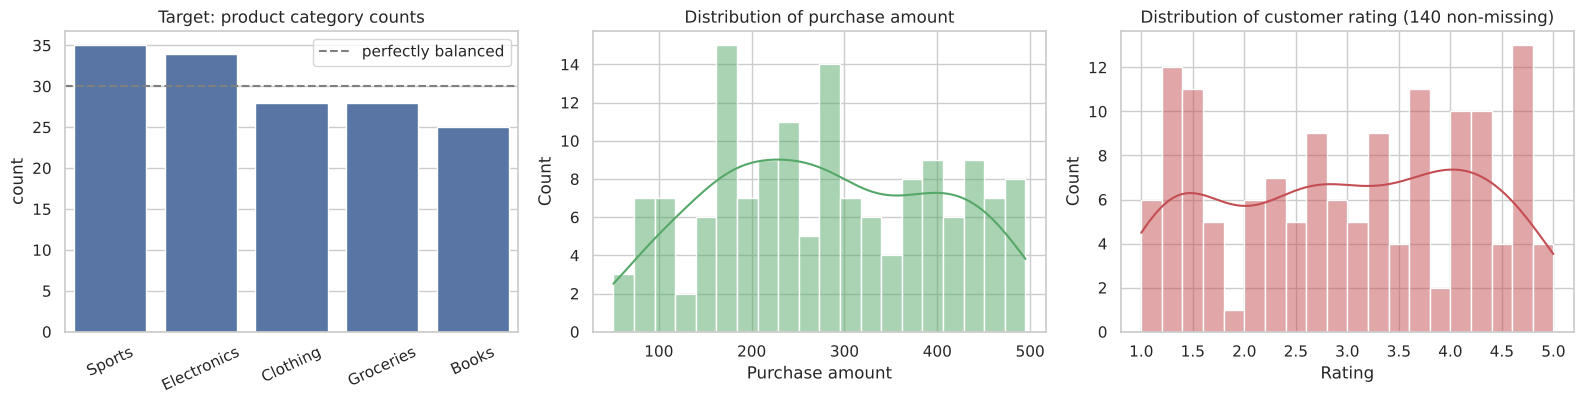

product_category
Sports         35
Electronics    34
Clothing       28
Groceries      28
Books          25


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

order = merged["product_category"].value_counts().index
sns.countplot(data=merged, x="product_category", order=order, ax=axes[0], color="#4C72B0")
axes[0].axhline(len(merged) / 5, ls="--", c="grey", label="perfectly balanced")
axes[0].set_title("Target: product category counts"); axes[0].set_xlabel(""); axes[0].legend()
axes[0].tick_params(axis="x", rotation=25)

sns.histplot(merged["purchase_amount"], bins=20, kde=True, ax=axes[1], color="#55A868")
axes[1].set_title("Distribution of purchase amount"); axes[1].set_xlabel("Purchase amount")

sns.histplot(merged["customer_rating"].dropna(), bins=20, kde=True, ax=axes[2], color="#C44E52")
axes[2].set_title("Distribution of customer rating (140 non-missing)"); axes[2].set_xlabel("Rating")
plt.tight_layout(); plt.show()
print(merged["product_category"].value_counts().to_string())

**Interpretation.**
- *Target:* the five categories are fairly balanced (25 to 35 transactions each, 17 to 23% of rows). No class dominates, so a majority-class baseline can only reach about 23% accuracy and random guessing reaches 20%. That is the bar a real model has to beat.
- *Purchase amount:* spread almost evenly between about 50 and 500 with no long tail, so there is no need to remove or cap values.
- *Rating:* spread across the whole 1 to 5 range with no strong peak, and 10 missing values.

### 3.3 Outliers: purchase amount and engagement by category

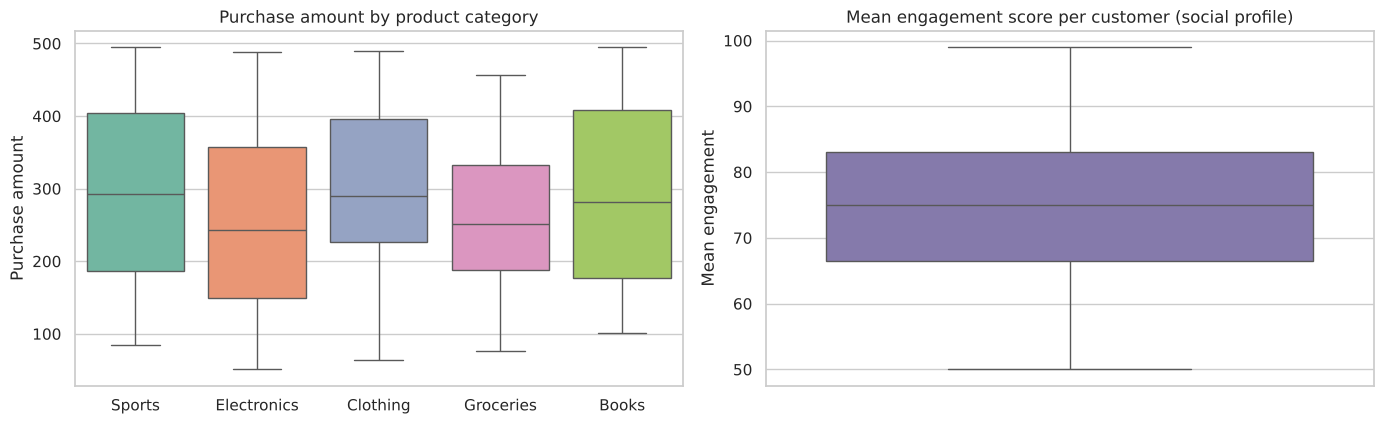

IQR-rule outliers in purchase_amount: 0


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
sns.boxplot(data=merged, x="product_category", y="purchase_amount", order=order, ax=axes[0], palette="Set2")
axes[0].set_title("Purchase amount by product category"); axes[0].set_xlabel(""); axes[0].set_ylabel("Purchase amount")
cust = merged.drop_duplicates("customer_id").dropna(subset=["mean_engagement"])
sns.boxplot(y=cust["mean_engagement"], ax=axes[1], color="#8172B3")
axes[1].set_title("Mean engagement score per customer (social profile)"); axes[1].set_ylabel("Mean engagement")
plt.tight_layout(); plt.show()

q1, q3 = merged.purchase_amount.quantile([.25, .75]); iqr = q3 - q1
out = ((merged.purchase_amount < q1 - 1.5*iqr) | (merged.purchase_amount > q3 + 1.5*iqr)).sum()
print("IQR-rule outliers in purchase_amount:", out)

**Interpretation.** The IQR rule flags **no outliers** in purchase amount, and the boxes for all five categories overlap heavily, with medians in a similar range. Spending alone does not separate the categories. Engagement has a wide spread but no extreme points, so no outlier treatment was applied.

### 3.4 Correlations

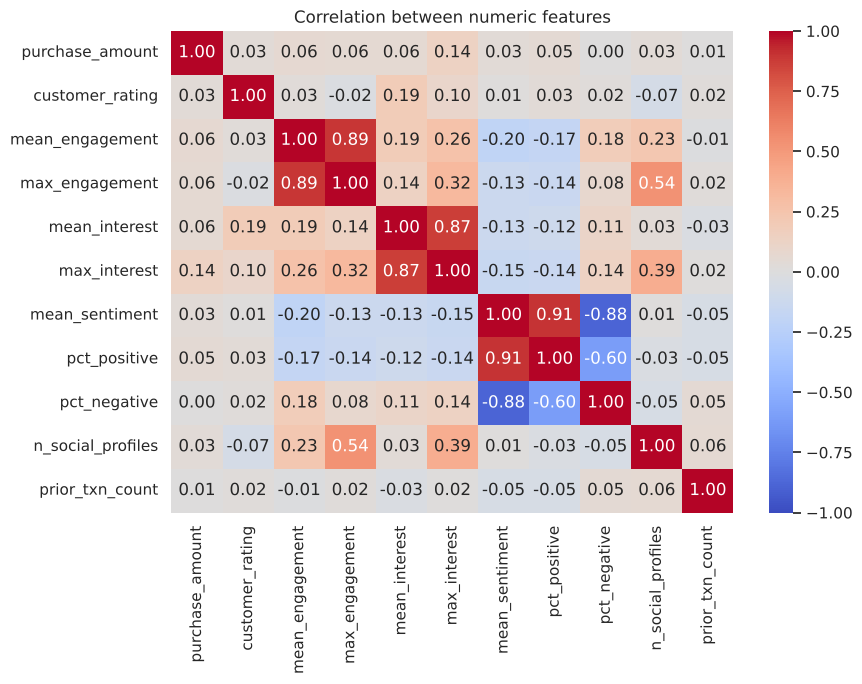

Strongest feature pairs (|r|):
mean_sentiment   pct_positive         0.91
mean_engagement  max_engagement       0.89
mean_sentiment   pct_negative         0.88
mean_interest    max_interest         0.87
pct_positive     pct_negative         0.60
max_engagement   n_social_profiles    0.54


In [12]:
corr_cols = ["purchase_amount", "customer_rating", "mean_engagement", "max_engagement", "mean_interest",
             "max_interest", "mean_sentiment", "pct_positive", "pct_negative", "n_social_profiles",
             "prior_txn_count"]
corr = merged[corr_cols].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between numeric features"); plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().abs().sort_values(ascending=False)
print("Strongest feature pairs (|r|):"); print(pairs.head(6).round(2).to_string())

**Interpretation.** The only strong correlations are between features that are built from the same data (for example `mean_engagement` with `max_engagement`, or `pct_positive` with `mean_sentiment`). They carry nearly the same information, which is acceptable for tree models and regularised logistic regression but worth noting. Transaction features (amount, rating) are essentially uncorrelated with the social features, so the two data sources add information independently of each other.

### 3.5 Social behaviour versus product category

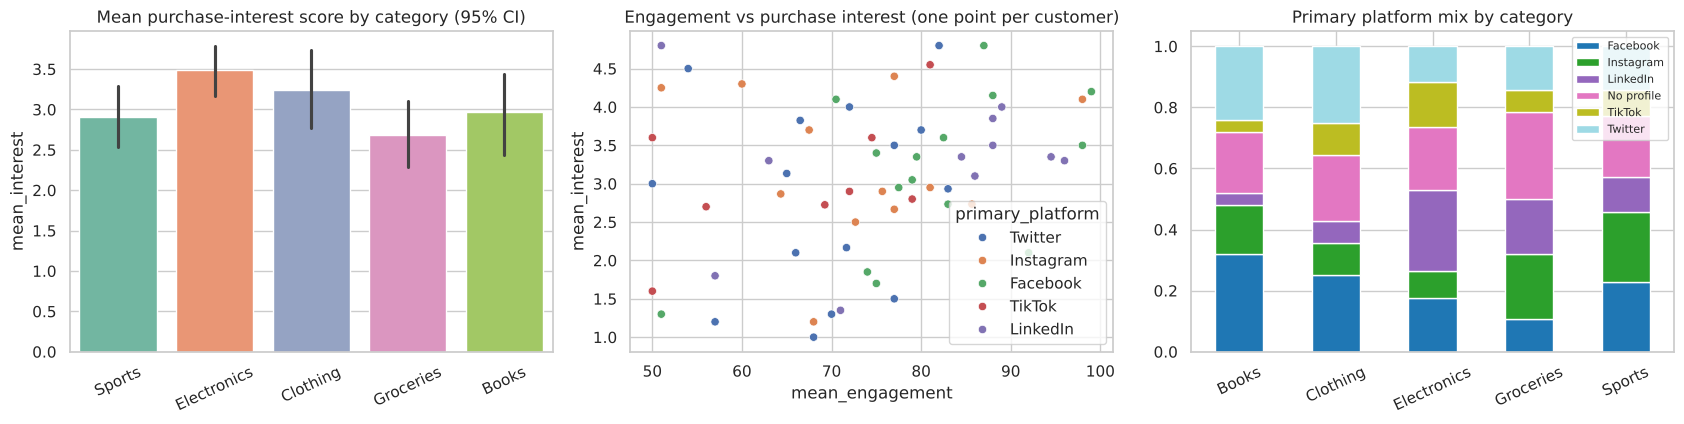

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))

sns.barplot(data=merged.dropna(subset=["mean_interest"]), x="product_category", y="mean_interest",
            order=order, ax=axes[0], palette="Set2", errorbar=("ci", 95))
axes[0].set_title("Mean purchase-interest score by category (95% CI)"); axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=25)

sns.scatterplot(data=cust, x="mean_engagement", y="mean_interest", hue="primary_platform", ax=axes[1])
axes[1].set_title("Engagement vs purchase interest (one point per customer)")

sent = pd.crosstab(merged["product_category"], merged["primary_platform"].fillna("No profile"), normalize="index")
sent.plot.bar(stacked=True, ax=axes[2], colormap="tab20"); axes[2].set_title("Primary platform mix by category")
axes[2].set_xlabel(""); axes[2].tick_params(axis="x", rotation=25); axes[2].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

**Interpretation.** Average purchase-interest is highest for Electronics (about 3.5) and lowest for Groceries (about 2.7), and the intervals for those two barely touch. This is the most visible social pattern in the data, but across all five categories it is not statistically significant (tested in section 4). Engagement and interest are only weakly related (r about 0.2 per customer). The platform mix does vary between categories (for example, LinkedIn is more common among Electronics buyers), but each category has few customers, so these differences are small samples and may be chance. The next section tests this formally.

## 4. Feature-signal check
Before modelling, test whether each feature is statistically related to `product_category`. Numeric features use the Kruskal-Wallis test (distribution differs between categories?) and categorical features use a chi-square test. With about 10 tests, one result under 0.05 is expected by chance alone, so the Bonferroni-adjusted threshold is 0.05 / 10 = **0.005**.

In [14]:
rows = []
for c in ["purchase_amount", "customer_rating", "mean_engagement", "mean_interest", "mean_sentiment", "prior_txn_count"]:
    groups = [g[c].dropna() for _, g in merged.groupby("product_category")]
    rows.append((c, "Kruskal-Wallis", stats.kruskal(*groups).pvalue))
for c in ["primary_platform", "prev_category", "is_weekend", "purchase_month"]:
    ct = pd.crosstab(merged[c].fillna("Unknown"), merged["product_category"])
    rows.append((c, "Chi-square", stats.chi2_contingency(ct)[1]))
sig = pd.DataFrame(rows, columns=["feature", "test", "p_value"]).sort_values("p_value")
sig["significant at 0.05"] = sig.p_value < 0.05
sig["significant after Bonferroni (0.005)"] = sig.p_value < 0.005
display(sig.round(3).reset_index(drop=True))

hist = merged[merged.prev_category != "None"]
same = int((hist.prev_category == hist.product_category).sum())
exp = sum((merged.product_category.value_counts(normalize=True)[c]) * (hist.prev_category == c).sum()
          for c in merged.product_category.unique())
print(f"\nRepeat buyers: {same} of {len(hist)} bought the same category as last time "
      f"(expected by chance: {exp:.1f}); binomial test p = {stats.binomtest(same, len(hist), exp/len(hist)).pvalue:.2f}")

,feature,test,p_value,significant at 0.05,significant after Bonferroni (0.005)
0,prev_category,Chi-square,0.024,True,False
1,purchase_month,Chi-square,0.055,False,False
2,mean_interest,Kruskal-Wallis,0.069,False,False
3,prior_txn_count,Kruskal-Wallis,0.223,False,False
4,is_weekend,Chi-square,0.242,False,False
5,purchase_amount,Kruskal-Wallis,0.349,False,False
6,primary_platform,Chi-square,0.548,False,False
7,customer_rating,Kruskal-Wallis,0.639,False,False
8,mean_engagement,Kruskal-Wallis,0.725,False,False
9,mean_sentiment,Kruskal-Wallis,0.745,False,False



Repeat buyers: 16 of 75 bought the same category as last time (expected by chance: 15.1); binomial test p = 0.77


**Interpretation.** No feature passes the Bonferroni threshold. `prev_category` reaches p about 0.02, but this is driven by the large "None" row (customers with no earlier purchase) and very small cell counts, and repeat buyers pick the same category as last time no more often than chance predicts. `mean_interest` and `purchase_month` are borderline (p about 0.06 to 0.07). **Conclusion:** the features carry little or no usable signal about the product category, so we should expect any model to perform close to chance. The modelling results below test that expectation.

## 5. Model training and evaluation
**Models:** Logistic Regression, Random Forest, XGBoost, plus a majority-class baseline.
**Preprocessing (inside the pipeline, fit on training folds only):** median imputation and scaling for numeric features, "Unknown" imputation and one-hot encoding for categorical features.
**Validation:** 5-fold stratified cross-validation **grouped by customer**, repeated 5 times with different shuffles. Grouping matters because social features are identical for every transaction of the same customer. A random row split would put the same customer in train and test, so the model could memorise customers and the scores would look better than they really are.
**Metrics:** accuracy, macro F1 and log loss (the "loss" the assignment asks for; lower is better).

In [15]:
df = pm.load()
le = pm.LabelEncoder(); y = le.fit_transform(df[pm.TARGET])
X = df[pm.NUM + pm.CAT]; groups = df["customer_id"].values

models = pm.get_models(len(le.classes_))
results = pm.cross_validate(models, X, y, groups, n_repeats=5)
results

,Accuracy,Acc std,Macro F1,Log loss
Baseline (majority),0.224,0.014,0.073,1.602
Logistic Regression,0.223,0.057,0.183,1.787
Random Forest,0.218,0.060,0.161,1.651
XGBoost,0.197,0.044,0.167,1.800


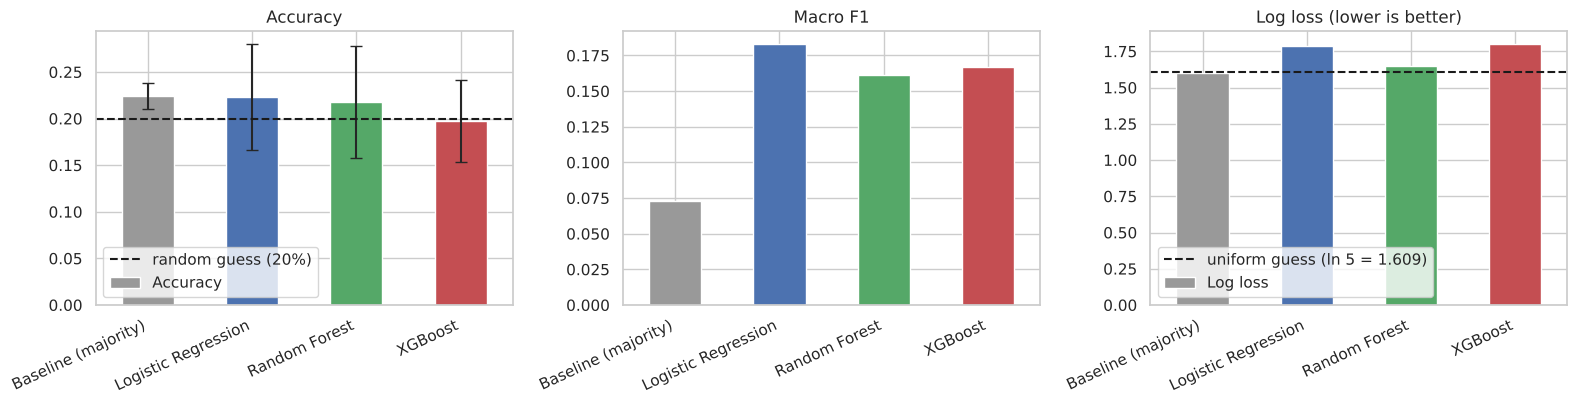

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
cols = ["#999999", "#4C72B0", "#55A868", "#C44E52"]
results["Accuracy"].plot.bar(ax=axes[0], color=cols, yerr=results["Acc std"], capsize=4)
axes[0].axhline(0.2, ls="--", c="k", label="random guess (20%)"); axes[0].set_title("Accuracy"); axes[0].legend()
results["Macro F1"].plot.bar(ax=axes[1], color=cols); axes[1].set_title("Macro F1")
results["Log loss"].plot.bar(ax=axes[2], color=cols)
axes[2].axhline(np.log(5), ls="--", c="k", label="uniform guess (ln 5 = 1.609)"); axes[2].set_title("Log loss (lower is better)"); axes[2].legend()
for a in axes: a.set_xticklabels(results.index, rotation=25, ha="right")
plt.tight_layout(); plt.show()

**Interpretation.**
- All three models score about 20 to 22% accuracy, **no better than the majority-class baseline (22%) or random guessing (20%)**. The spread between folds (about 5 to 6 points) is larger than the gaps between models, so we cannot say any model is better than another.
- Macro F1 is higher for the models than for the baseline only because the baseline always predicts a single class. Accuracy and log loss are the fairer comparison here.
- Log loss is **worse** than the baseline for every model (baseline about 1.60; models 1.65 to 1.80). The models are overfitting noise and produce overconfident probabilities, which is consistent with the near-zero feature signal found in section 4.
- Random Forest has the lowest log loss of the three, so it is the model we save and use. This is a choice among weak options, not evidence that it has learned something real.

### 5.1 Where does the best model make its predictions? (confusion matrix and feature importance)

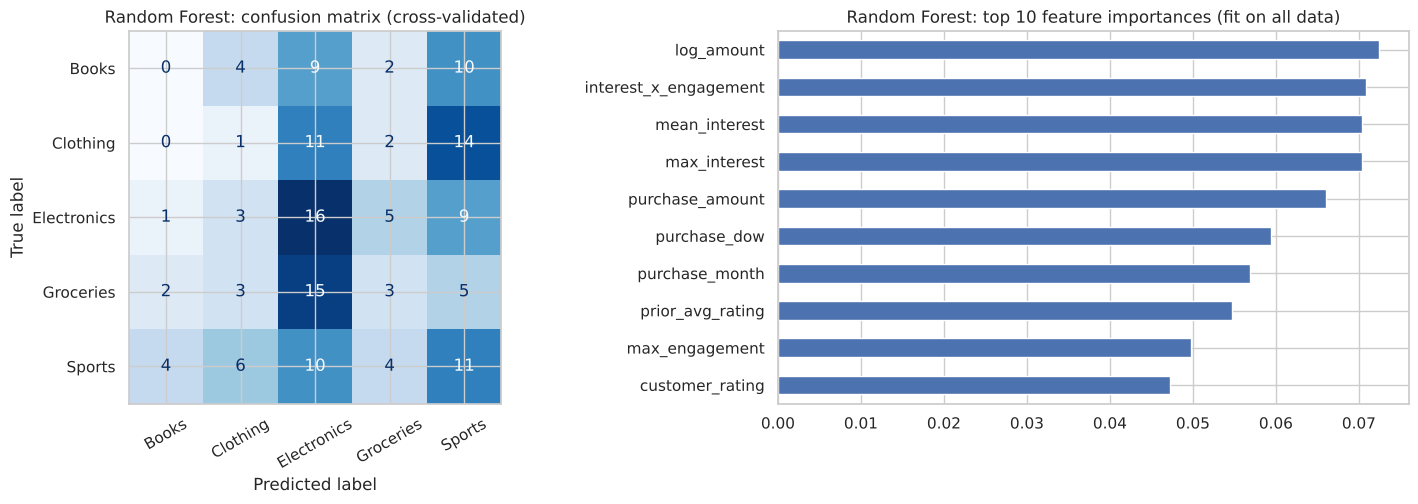

In [17]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

rf = pm.get_models(len(le.classes_))["Random Forest"]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=pm.SEED)
pred = cross_val_predict(rf, X, y, cv=cv, groups=groups)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=le.classes_).plot(ax=axes[0], cmap="Blues", colorbar=False, xticks_rotation=30)
axes[0].set_title("Random Forest: confusion matrix (cross-validated)")

rf.fit(X, y)
names = rf.named_steps["pre"].get_feature_names_out()
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=[n.split("__")[1] for n in names]).nlargest(10)
imp.iloc[::-1].plot.barh(ax=axes[1], color="#4C72B0"); axes[1].set_title("Random Forest: top 10 feature importances (fit on all data)")
plt.tight_layout(); plt.show()

**Interpretation.** The correct predictions (the diagonal) make up only about 21% of the matrix, which matches the near-chance accuracy. The model also leans toward predicting Electronics and Sports and rarely predicts Books or Clothing, which suggests it is picking up small quirks of the training data rather than real patterns. Feature importances are spread over many features with no clear leader: continuous features like `purchase_amount` tend to rank high in random forests simply because they offer many split points, not because they are informative. Treat the importances as a description of the model, not as findings about customers.

## 6. Using the model: `predict_product`

In [18]:
from product_predictor import predict_product

for cid in [151, "A192", 171]:           # 171 has no social profile
    r = predict_product(cid)
    print(f"Customer {r['customer_id']}: recommend {r['top_prediction']} ({r['confidence']:.0%})  top-3: {r['top_k']}")

try:
    predict_product(9999)
except KeyError as e:
    print("Access denied / unknown customer ->", e)

Customer 151: recommend Sports (31%)  top-3: [('Sports', 0.314), ('Groceries', 0.242), ('Clothing', 0.158)]
Customer 192: recommend Books (25%)  top-3: [('Books', 0.248), ('Electronics', 0.23), ('Sports', 0.23)]
Customer 171: recommend Clothing (26%)  top-3: [('Clothing', 0.255), ('Sports', 0.221), ('Groceries', 0.2)]
Access denied / unknown customer -> 'Customer 9999 has no transaction history.'


In the demo, `predict_product(customer_id)` is called only after the face is recognised and the voice is approved. The customer ID comes from the face-recognition model. Unknown IDs raise a `KeyError`, which the app shows as an access-denied message.

## 7. Conclusions and limitations
- **Merge:** the two sources use different ID formats and the social file has duplicates and several rows per customer. Normalising the key, removing duplicates, aggregating per customer and left-joining kept exactly one row per transaction (150), instead of the inflated counts a naive join produces. All validation checks pass.
- **EDA:** the target is balanced, amounts have no outliers, and features from the two sources are independent of each other. No feature shows a reliable relationship with product category.
- **Model:** with grouped cross-validation, none of the models beats the majority-class baseline (accuracy about 22%, log loss about 1.60). The data itself is the limiting factor: 150 transactions, 75 customers, 30 of them with a single purchase, and features that carry almost no signal about the category.
- **What would help:** more transactions per customer, item-level purchase details, or richer social features (for example, the topics a customer engages with) rather than only scores.
- **For the demo:** the model's output should be presented as a recommendation with its confidence, since confidence is low (about 25 to 31%).